# Component B – Data Quality & Profiling
**Dataset:** UCI Online Retail (DOI 10.24432/C5BW33). **Input:** the untouched raw Excel file. **Output:** charts in `figures/`, tables in `output/`.

Order of work: (1) profile structure, types, distributions, completeness and uniqueness; (2) test each quality dimension; (3) check how the issues overlap; (4) record every issue with a root-cause hypothesis and its downstream impact. Component C responds to the issue IDs (Q1, Q2, ...) created here.

In [1]:
import os, sys
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")   # the shared rules file is in the project root
from quality_rules import is_admin_code, is_cancellation, is_catalogue_format, needs_case_fix, standard_stock_code, standard_description

os.makedirs("figures", exist_ok=True)
os.makedirs("output", exist_ok=True)

df = pd.read_excel("../data/raw/Online Retail.xlsx")
N = len(df)
df.shape

(541909, 8)

## 1. Structure and variable types
`dtypes` alone hides a problem: `object` columns can hold a mix of Python types, so the table also counts the real types inside each column.

In [2]:
pd.DataFrame({
    "pandas_type": df.dtypes.astype(str),
    "python_types_in_column": [sorted({type(v).__name__ for v in df[c].dropna()}) for c in df.columns],
    "distinct_values": df.nunique(),
})

,pandas_type,python_types_in_column,distinct_values
InvoiceNo,object,"[int, str]",25900
StockCode,object,"[int, str]",4070
Description,object,"[int, str]",4223
Quantity,int64,[int],722
InvoiceDate,datetime64[us],[Timestamp],23260
UnitPrice,float64,[float],1630
CustomerID,float64,[float],4372
Country,str,[str],38


`InvoiceNo` and `StockCode` mix numbers and text because Excel stored numeric-looking codes as numbers. `CustomerID` is a decimal only because missing values force pandas to use floats: an identifier should never be stored as 17850.0. One `Description` value is even the integer 20713.

## 2. Value distributions

In [3]:
print(df[["Quantity", "UnitPrice"]].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(2))
print("\nInvoiceDate from", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("\nTop 5 countries (% of rows):")
print((df["Country"].value_counts(normalize=True) * 100).round(2).head(5))
print("\nRows per weekday (0 = Monday):", df["InvoiceDate"].dt.day_of_week.value_counts().sort_index().to_dict())
print("Invoice number patterns:", df["InvoiceNo"].astype(str).str.replace(r"\d", "9", regex=True).value_counts().to_dict())

        Quantity  UnitPrice
count  541909.00  541909.00
mean        9.55       4.61
std       218.08      96.76
min    -80995.00  -11062.06
1%         -2.00       0.19
25%         1.00       1.25
50%         3.00       2.08
75%        10.00       4.13
99%       100.00      18.00
max     80995.00   38970.00

InvoiceDate from 2010-12-01 08:26:00 to 2011-12-09 12:50:00

Top 5 countries (% of rows):
Country
United Kingdom    91.43
Germany            1.75
France             1.58
EIRE               1.51
Spain              0.47
Name: proportion, dtype: float64

Rows per weekday (0 = Monday): {0: 95111, 1: 101808, 2: 94565, 3: 103857, 4: 82193, 6: 64375}


Invoice number patterns: {'999999': 532618, 'C999999': 9288, 'A999999': 3}


The file has **no Saturdays at all** (weekday 5 is absent), and the mean quantity (9.55) sits far from the median (3) with a standard deviation of 218: a sign of extreme values. Both are examined below.

## 3. Completeness

In [4]:
missing = df.isnull().sum()
missing_pct = (missing / N * 100).round(2)
display(pd.DataFrame({"missing": missing, "percent": missing_pct}))

# Missing CustomerID by invoice, month, country and price
no_customer = df["CustomerID"].isna()
per_invoice = no_customer.groupby(df["InvoiceNo"].astype(str)).mean()
print("Invoices partly missing CustomerID:", ((per_invoice > 0) & (per_invoice < 1)).sum(), "of", len(per_invoice))
print("Median UnitPrice (price > 0): with ID", df.loc[~no_customer & (df.UnitPrice > 0), "UnitPrice"].median(),
      "| without ID", df.loc[no_customer & (df.UnitPrice > 0), "UnitPrice"].median())
missing_by_month = (no_customer.groupby(df["InvoiceDate"].dt.to_period("M")).mean() * 100).round(1)
print("Missing CustomerID % by month: min", missing_by_month.min(), "max", missing_by_month.max())
by_country = no_customer.groupby(df["Country"]).agg(["sum", "mean"]).sort_values("sum", ascending=False).head(4)
print(by_country.round(3))

# Description: what do the rows without a name look like?
no_desc = df["Description"].isna()
print("\nMissing Description rows:", no_desc.sum(), "| price 0:", (no_desc & (df.UnitPrice == 0)).sum(),
      "| no CustomerID:", (no_desc & no_customer).sum())

,missing,percent
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Invoices partly missing CustomerID: 0 of 25900
Median UnitPrice (price > 0): with ID 1.95 | without ID 3.29
Missing CustomerID % by month: min 16.5 max 37.7
                   sum   mean
Country                      
United Kingdom  133600  0.270
EIRE               711  0.087
Hong Kong          288  1.000
Unspecified        202  0.453

Missing Description rows: 1454 | price 0: 1454 | no CustomerID: 1454


In [5]:
# Invoice-level view of missing CustomerID, and a test of whether the rate varies by month
import json
from scipy.stats import chi2_contingency

invoices = df.assign(no_customer=no_customer, invoice=df["InvoiceNo"].astype(str)).groupby("invoice").agg(
    no_customer=("no_customer", "first"), month=("InvoiceDate", lambda s: s.iloc[0].strftime("%Y-%m")), lines=("StockCode", "size"))
monthly = pd.crosstab(invoices["month"], invoices["no_customer"])
invoice_rate = (monthly[True] / monthly.sum(axis=1) * 100).round(1)
chi2, p_value, dof, _ = chi2_contingency(monthly)
profile = {
    "row_level_percent_by_month_min": float(missing_by_month.min()), "row_level_percent_by_month_max": float(missing_by_month.max()),
    "invoice_level_percent_by_month_min": float(invoice_rate.min()), "invoice_level_percent_by_month_max": float(invoice_rate.max()),
    "invoices_without_customer": int(invoices["no_customer"].sum()), "invoices_total": int(len(invoices)),
    "median_lines_per_invoice_with_customer": float(invoices.loc[~invoices["no_customer"], "lines"].median()),
    "median_lines_per_invoice_without_customer": float(invoices.loc[invoices["no_customer"], "lines"].median()),
    "chi_square_month_by_missing": round(float(chi2), 1), "degrees_of_freedom": int(dof), "p_value_below_0_001": bool(p_value < 0.001),
    "cramers_v": round(float((chi2 / monthly.values.sum()) ** 0.5), 3),
}
with open("output/missing_customer_profile.json", "w", encoding="utf-8", newline="\n") as handle:
    json.dump(profile, handle, indent=2)
profile

{'row_level_percent_by_month_min': 16.5,
 'row_level_percent_by_month_max': 37.7,
 'invoice_level_percent_by_month_min': 9.3,
 'invoice_level_percent_by_month_max': 20.6,
 'invoices_without_customer': 3710,
 'invoices_total': 25900,
 'median_lines_per_invoice_with_customer': 12.0,
 'median_lines_per_invoice_without_customer': 1.0,
 'chi_square_month_by_missing': 200.8,
 'degrees_of_freedom': 12,
 'p_value_below_0_001': True,
 'cramers_v': 0.088}

Row-level and invoice-level views answer different questions. Each invoice either has a customer or does not (never partly). The row-level rate is influenced by invoice size, so the invoice-level rate is reported as well. The rate varies by month, which is evidence against values being missing completely at random (Rubin, 1976). It does not show why they are missing: guest or offline orders and batched entries are possible explanations, and the file cannot distinguish them. Dropping those rows could bias customer analysis, which is why Component C keeps them.

## 4. Uniqueness

In [6]:
dup = df.duplicated()
dup_count = int(dup.sum())
revenue = df["Quantity"] * df["UnitPrice"]
print("Rows that exactly copy an earlier row:", dup_count, "|", round(dup_count / N * 100, 2), "%")
print("Revenue on those rows: GBP", round(revenue[dup].sum(), 2), "of", round(revenue.sum(), 2))
print("InvoiceNo + StockCode cannot be a key: repeated pairs =", int(df.duplicated(["InvoiceNo", "StockCode"]).sum()))
print("\nDistinct InvoiceNo", df.InvoiceNo.nunique(), "| distinct StockCode as stored", df.StockCode.astype(str).nunique(),
      "| after upper-casing", standard_stock_code(df.StockCode).nunique())
g = df.groupby(df.InvoiceNo.astype(str))
print("Invoices with >1 customer:", int((g.CustomerID.nunique() > 1).sum()), "| >1 country:", int((g.Country.nunique() > 1).sum()),
      "| >1 timestamp:", int((g.InvoiceDate.nunique() > 1).sum()))

Rows that exactly copy an earlier row: 5268 | 0.97 %
Revenue on those rows: GBP 21740.98 of 9747747.93
InvoiceNo + StockCode cannot be a key: repeated pairs = 10684



Distinct InvoiceNo 25900 | distinct StockCode as stored 4070 | after upper-casing 3958


Invoices with >1 customer: 0 | >1 country: 0 | >1 timestamp: 43


## 5. Validity and accuracy
The register uses these definitions, so that each issue is placed by what is actually wrong:

| Dimension | Question it asks | Example here |
|---|---|---|
| **Completeness** | Is a value present? | CustomerID missing |
| **Uniqueness** | Is each real-world event recorded once? | Exact duplicate rows |
| **Validity** | Does a value follow the stated rule, format or range? | Price of 0 or below; a code outside the documented format |
| **Accuracy** | Does a value match the real world? | An order of 80,995 units that was reversed minutes later |
| **Consistency** | Is the same thing represented in the same way throughout? | 85123a and 85123A; sales and reversals in one table |
| **Timeliness** | Is the data recent and complete enough for its use? | Final month stops on the 9th |

A value can be valid but inaccurate. We rarely have an outside source to confirm accuracy, so **Accuracy is used only where the data contains evidence of the true situation**.

A negative quantity is not automatically an error: UCI documents `C` invoices as cancellations. So the rows are split into the two cases, instead of being counted once as "negative" and again as "no C". Not every `C` row is a product coming back: some reverse postage, fees or discounts.


In [7]:
is_cancel = is_cancellation(df["InvoiceNo"])
neg_qty = df["Quantity"] < 0
neg_not_cancel = neg_qty & ~is_cancel
bad_price = df["UnitPrice"] <= 0

print("Quantity < 0:", int(neg_qty.sum()), "= cancellations", int((neg_qty & is_cancel).sum()), "+ no 'C' invoice", int(neg_not_cancel.sum()))
print("'C' rows: real products", int((is_cancel & ~is_admin_code(df.StockCode)).sum()), "| administrative codes", int((is_cancel & is_admin_code(df.StockCode)).sum()), "| no CustomerID", int((is_cancel & no_customer).sum()))
print("'C' invoices with a positive quantity:", int((is_cancel & ~neg_qty).sum()))
print("Negative qty, no 'C': price 0 =", int((neg_not_cancel & (df.UnitPrice == 0)).sum()),
      "| no CustomerID =", int((neg_not_cancel & no_customer).sum()))
print("Their commonest notes:", df.loc[neg_not_cancel, "Description"].dropna().astype(str).str.lower().value_counts().head(6).to_dict())
print("\nUnitPrice <= 0:", int(bad_price.sum()), "= zero", int((df.UnitPrice == 0).sum()), "+ negative", int((df.UnitPrice < 0).sum()))
print(df.loc[df.UnitPrice < 0, ["InvoiceNo", "StockCode", "Description", "UnitPrice"]])
print("\nPrice 0 and a real customer (possible free items):", int(((df.UnitPrice == 0) & ~no_customer).sum()))

Quantity < 0: 10624 = cancellations 9288 + no 'C' invoice 1336


'C' rows: real products 8704 | administrative codes 584 | no CustomerID 383
'C' invoices with a positive quantity: 0
Negative qty, no 'C': price 0 = 1336 | no CustomerID = 1336
Their commonest notes: {'check': 123, 'damaged': 57, 'damages': 46, '?': 41, 'sold as set on dotcom': 20, 'thrown away': 9}

UnitPrice <= 0: 2517 = zero 2515 + negative 2
       InvoiceNo StockCode      Description  UnitPrice
299983   A563186         B  Adjust bad debt  -11062.06
299984   A563187         B  Adjust bad debt  -11062.06

Price 0 and a real customer (possible free items): 40


## 6. Outliers
The IQR rule (Q3 + 1.5 × IQR) is checked first, then the largest values are read individually.

In [8]:
sales = df[(df.Quantity > 0) & (df.UnitPrice > 0) & ~is_cancel]
q1, q3 = sales.Quantity.quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
print(f"IQR upper fence for Quantity: {fence} -> {(sales.Quantity > fence).sum():,} rows ({(sales.Quantity > fence).mean():.1%})")
print("99.9th percentile:", sales.Quantity.quantile(0.999))
display(sales.nlargest(4, "Quantity")[["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice", "CustomerID", "InvoiceDate"]])
display(df[is_cancel].nsmallest(2, "Quantity")[["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "CustomerID", "InvoiceDate"]])

IQR upper fence for Quantity: 23.5 -> 56,363 rows (10.6%)
99.9th percentile: 449.7939999999944


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,2011-12-09 09:15:00
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,2011-01-18 10:01:00
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,12901.0,2011-10-27 12:26:00
206121,554868,22197,SMALL POPCORN HOLDER,4300,0.72,13135.0,2011-05-27 10:52:00


,InvoiceNo,StockCode,Quantity,UnitPrice,CustomerID,InvoiceDate
540422,C581484,23843,-80995,2.08,16446.0,2011-12-09 09:27:00
61624,C541433,23166,-74215,1.04,12346.0,2011-01-18 10:17:00


The IQR rule flags too many rows to be useful. UCI says many customers are wholesalers, so most of those are real bulk orders and the rule is **not** used for removal. The two largest sales are different: 80,995 and 74,215 units, each exactly reversed by a `C` invoice minutes later. They do not appear to represent real demand.

## 7. Validity and consistency
The UCI documentation says `StockCode` is a 5-digit number. Three different things break that rule and must not be merged.

**Scope of Q9:** every row whose stored StockCode differs from its upper-case form, which is exactly the set of rows Component C changes. It has two parts: lower-case catalogue variants (such as 85123a) and lower-case administrative codes (such as gift_0001_20 and m).


In [9]:
code = df["StockCode"].astype(str)
strict = code.str.fullmatch(r"\d{5}")
catalogue = is_catalogue_format(code)
admin = is_admin_code(code)
other = ~catalogue & ~admin

print("Exactly 5 digits:", int(strict.sum()))
print("Not 5 digits, total:", int((~strict).sum()))
print("  a) 5 digits + letter(s), product variants:", int((catalogue & ~strict).sum()))
print("  b) administrative codes:", int(admin.sum()), df.loc[admin, "StockCode"].astype(str).str.upper().value_counts().head(6).to_dict())
print("  c) other non-standard product codes:", int(other.sum()), df.loc[other, "Description"].dropna().astype(str).value_counts().head(5).to_dict())

lower = needs_case_fix(code)
assert (lower & ~catalogue & ~admin).sum() == 0   # the two parts below cover all of Q9
print("\nQ9 lower-case StockCode rows:", int(lower.sum()), "= catalogue variants", int((lower & catalogue).sum()),
      "+ administrative codes", int((lower & admin).sum()), code[lower & admin].value_counts().to_dict())
print("Example catalogue variants:", code[lower & catalogue].value_counts().head(3).to_dict())
print("Q9 rows that also lack CustomerID:", int((lower & no_customer).sum()), "of", int(lower.sum()))

text = df["Description"].dropna().astype(str)
clean_text = standard_description(text)
print("Description with outer spaces:", int((text != text.str.strip()).sum()), "| repeated inner spaces:", int(text.str.contains(r"\s{2,}").sum()))
print("Distinct descriptions as stored:", text.nunique(), "| after trimming/collapsing spaces:", clean_text.nunique())
per_code = pd.DataFrame({"c": standard_stock_code(df.loc[text.index, "StockCode"]), "d": clean_text}).groupby("c")["d"].nunique()
print("StockCodes with more than one description:", int((per_code > 1).sum()), "of", len(per_code))
print("\nCountry labels that are not standard country names:", df["Country"][df["Country"].isin(["EIRE", "RSA", "USA", "Unspecified", "European Community", "Channel Islands"])].value_counts().to_dict())

Exactly 5 digits: 487036
Not 5 digits, total: 54873
  a) 5 digits + letter(s), product variants: 51878
  b) administrative codes: 2946 {'POST': 1256, 'DOT': 710, 'M': 572, 'C2': 144, 'D': 77, 'S': 63}
  c) other non-standard product codes: 49 {'GIRLS PARTY BAG': 13, 'BOYS PARTY BAG': 11, 'ebay': 5, 'BOXED GLASS ASHTRAY': 4, 'PADS TO MATCH ALL CUSHIONS': 4}



Q9 lower-case StockCode rows: 1977 = catalogue variants 1942 + administrative codes 35 {'gift_0001_20': 10, 'gift_0001_10': 9, 'gift_0001_30': 8, 'gift_0001_50': 4, 'gift_0001_40': 3, 'm': 1}
Example catalogue variants: {'47566b': 102, '15056n': 84, '72349b': 82}
Q9 rows that also lack CustomerID: 1977 of 1977


Description with outer spaces: 113452 | repeated inner spaces: 22290


Distinct descriptions as stored: 4223 | after trimming/collapsing spaces: 4203


StockCodes with more than one description: 638 of 3848

Country labels that are not standard country names: {'EIRE': 8196, 'Channel Islands': 758, 'Unspecified': 446, 'USA': 291, 'European Community': 61, 'RSA': 58}


**Q9 and missing CustomerID overlap completely:** every lower-case code occurs on a row without a CustomerID. The lower-case spelling is therefore tied to whichever process created those no-customer invoices. The file cannot show what that process was, so the root cause remains a hypothesis.


## 8. Timeliness and documentation accuracy

In [10]:
print("Coverage:", df.InvoiceDate.min().date(), "to", df.InvoiceDate.max().date(), "=", (df.InvoiceDate.max() - df.InvoiceDate.min()).days, "days")
print("Rows per month:", {str(k): int(v) for k, v in df.groupby(df.InvoiceDate.dt.to_period("M")).size().items()})
print("Newest record year:", df.InvoiceDate.max().year)
print("UCI metadata says 'Has Missing Values: no'; profiling found", int(df.isna().any(axis=1).sum()), "rows with a missing value")

Coverage: 2010-12-01 to 2011-12-09 = 373 days
Rows per month: {'2010-12': 42481, '2011-01': 35147, '2011-02': 27707, '2011-03': 36748, '2011-04': 29916, '2011-05': 37030, '2011-06': 36874, '2011-07': 39518, '2011-08': 35284, '2011-09': 50226, '2011-10': 60742, '2011-11': 84711, '2011-12': 25525}
Newest record year: 2011
UCI metadata says 'Has Missing Values: no'; profiling found 135080 rows with a missing value


December 2011 stops on the 9th, so comparing it with whole months would look like a collapse in sales. The newest record is from 2011, so the file is suited to method work, not to current business decisions.

## 9. Overlap between issues
One row can have several problems, so **the issue counts cannot be added up**. This table shows how much they overlap.

In [11]:
flags = pd.DataFrame({
    "Q1 Missing CustomerID": no_customer,
    "Q2 Missing Description": no_desc,
    "Q3 Exact duplicate": dup,
    "Q4 Cancellation": is_cancel,
    "Q5 Negative qty, no 'C'": neg_not_cancel,
    "Q6 UnitPrice <= 0": bad_price,
    "Q7 Administrative code": admin,
    "Q9 Lower-case StockCode": lower,
})
overlap = pd.DataFrame({
    "rows": flags.sum(),
    "also_has_another_issue": [(flags[c] & (flags.drop(columns=c).sum(axis=1) > 0)).sum() for c in flags],
})
display(overlap)
any_issue = flags.any(axis=1)
without_customer_issue = flags.drop(columns="Q1 Missing CustomerID").any(axis=1)
print(f"Rows with at least one issue: {any_issue.sum():,} ({any_issue.mean():.2%}); simple sum of the counts would be {int(flags.sum().sum()):,}")
print(f"Rows with an issue other than missing CustomerID: {without_customer_issue.sum():,} ({without_customer_issue.mean():.2%})")

,rows,also_has_another_issue
Q1 Missing CustomerID,135080,5635
Q2 Missing Description,1454,1454
Q3 Exact duplicate,5268,81
Q4 Cancellation,9288,782
"Q5 Negative qty, no 'C'",1336,1336
Q6 UnitPrice <= 0,2517,2483
Q7 Administrative code,2946,1407
Q9 Lower-case StockCode,1977,1977


Rows with at least one issue: 150,756 (27.82%); simple sum of the counts would be 159,866
Rows with an issue other than missing CustomerID: 21,311 (3.93%)


## 10. Issue register
The root causes are **hypotheses**: the file contains no system documentation, so they are inferred from patterns and cannot be proved. Component C refers to these IDs.

The `downstream_impact` column gives **expected** effects. No predictive model was trained or evaluated in this project.

In [12]:
rows = lambda s: int(s.sum())
stored_as_number = lambda column: int(df[column].dropna().map(lambda v: not isinstance(v, str)).sum())
stored_as_text = lambda column: int(df[column].dropna().map(lambda v: isinstance(v, str)).sum())
id_columns = ["InvoiceNo", "StockCode", "CustomerID"]
variants = catalogue & ~strict
two_extremes = sales.nlargest(2, "Quantity")
register = [
 ("Q1","Completeness","CustomerID missing",rows(no_customer),"Unknown. Possible explanations are guest or offline orders, or batched entries; the ID is missing for whole invoices, never part of one","Expected: customer models (RFM, churn, lifetime value) would lose a quarter of rows, not completely at random","Keep and flag HasCustomerID"),
 ("Q2","Completeness","Description missing",rows(no_desc),"Internal stock entries: all have price 0 and no customer","Product text features and labels are empty","Remove; recorded in excluded or returns file"),
 ("Q3","Uniqueness","Exact duplicate rows",dup_count,"Repeated system entry; a genuine re-scan cannot be ruled out","Overstates quantity and revenue; repeated rows leak between train and test sets","Remove repeats, keep first; recorded in excluded file"),
 ("Q4","Consistency","Cancellations mixed with sales",rows(is_cancel),"Sales and reversals share one table by design","Negative demand distorts forecasting and revenue totals","Move to returns file as product cancellation or administrative reversal; flag matching sales"),
 ("Q5","Validity","Negative quantity without 'C'",rows(neg_not_cancel),"Warehouse corrections typed into the sales system (notes such as 'damaged', 'check')","Treated as returns by mistake; corrupts demand signal","Move to returns file as stock adjustment"),
 ("Q6","Validity","UnitPrice zero or negative",rows(bad_price),"Stock notes, a few free items, two bad-debt accounting entries","Price and revenue models receive values that are not valid sale prices","Remove; recorded in excluded file"),
 ("Q7","Consistency","Administrative StockCodes",rows(admin),"Postage, fees and manual entries share the product field","Non-products rank as best sellers and enter recommendation graphs","Remove; recorded in excluded file"),
 ("Q8","Validity","Variant codes break documented 5-digit format",rows(variants),"Letters mark colour or size; the documentation is incomplete","Numeric parsing fails; these are valid products and must be retained","No removal: format rule widened"),
 ("Q9","Consistency","Lower-case StockCode rows",rows(lower),"Every affected row lacks a CustomerID, suggesting one separate entry process; which process is unknown","One product is split into two, weakening product counts and graph edges","Upper-case all codes"),
 ("Q10","Consistency","Description with outer spaces",rows(text != text.str.strip()),"Unknown; export padding or manual entry are possibilities","Exact matching, grouping and text features treat one name as several","Trim and collapse spaces"),
 ("Q11","Consistency","StockCodes with several descriptions (codes, not rows)",int((per_code > 1).sum()),"Renamed products, typing variants, stock notes","Label noise when description is used as a category","Partly reduced; remainder documented; graph uses most frequent name"),
 ("Q12","Validity","Identifier columns stored with unsuitable or mixed types",len(id_columns),"Excel number storage and pandas missing-value handling","IDs treated as numbers can enter models as magnitudes; joins fail","Convert IDs to text / nullable integer"),
 ("Q13","Consistency","Non-standard country labels",rows(df.Country.isin(["EIRE","RSA","USA","Unspecified","European Community","Channel Islands"])),"Free-text country list without a standard","Joins to external country data fail; Unspecified is hidden missingness","Standard names and ISO 3166 codes"),
 ("Q14","Accuracy","Extreme quantities fully reversed",len(two_extremes),"Apparent order-entry mistakes, corrected within minutes",f"Two rows carry GBP {(two_extremes.Quantity * two_extremes.UnitPrice).sum():,.0f} of apparent sales and dominate quantity means and regressions","Remove; recorded in excluded file"),
 ("Q15","Timeliness","Partial final month; newest data 2011",rows(df.InvoiceDate >= "2011-12-01"),"Extract ended on 9 Dec 2011; no refreshed release","Seasonal comparisons are misleading; model drift against current behaviour","Documented; not fixable by cleaning"),
 ("Q16","Accuracy","Metadata states no missing values",rows(df.isna().any(axis=1)),"Field filled at repository level, not checked against the file","Users skip missing-value handling; reported to Component A","Documented in metadata record"),
]
register = pd.DataFrame(register, columns=["id","dimension","issue","rows_affected","root_cause_hypothesis","downstream_impact","component_c_response"])
register["percent_of_rows"] = (register["rows_affected"] / N * 100).round(2)
register["count_unit"] = "rows"
register.loc[register["id"] == "Q11", "count_unit"] = "product codes"
register.loc[register["id"] == "Q12", "count_unit"] = "identifier columns"
register.loc[register["id"].isin(["Q11", "Q12"]), "percent_of_rows"] = None   # not counted in rows
register["scope_note"] = register["id"].map({
    "Q4": f"Of these, {rows(is_cancel & ~admin):,} are product cancellations and {rows(is_cancel & admin):,} are administrative reversals; {rows(is_cancel & no_customer):,} have no CustomerID",
    "Q7": f"Includes {rows(is_cancel & admin):,} administrative reversals on 'C' invoices",
    "Q9": f"{rows(lower & catalogue):,} catalogue variants + {rows(lower & admin):,} administrative codes (also counted in Q7); all {rows(lower & no_customer):,} also lack a CustomerID",
    "Q12": f"Column-level issue. InvoiceNo: {stored_as_number('InvoiceNo'):,} numeric and {stored_as_text('InvoiceNo'):,} text values. StockCode: {stored_as_number('StockCode'):,} numeric and {stored_as_text('StockCode'):,} text values. CustomerID: all {stored_as_number('CustomerID'):,} present values stored as decimals",
})
register.to_csv("output/quality_issue_register.csv", index=False)
overlap.to_csv("output/issue_overlap.csv")
pd.set_option("display.max_colwidth", 60)
register[["id","dimension","issue","rows_affected","percent_of_rows"]]

,id,dimension,issue,rows_affected,percent_of_rows
0,Q1,Completeness,CustomerID missing,135080,24.93
1,Q2,Completeness,Description missing,1454,0.27
2,Q3,Uniqueness,Exact duplicate rows,5268,0.97
3,Q4,Consistency,Cancellations mixed with sales,9288,1.71
4,Q5,Validity,Negative quantity without 'C',1336,0.25
5,Q6,Validity,UnitPrice zero or negative,2517,0.46
6,Q7,Consistency,Administrative StockCodes,2946,0.54
7,Q8,Validity,Variant codes break documented 5-digit format,51878,9.57
8,Q9,Consistency,Lower-case StockCode rows,1977,0.36
9,Q10,Consistency,Description with outer spaces,113452,20.94


## 11. Visualisations

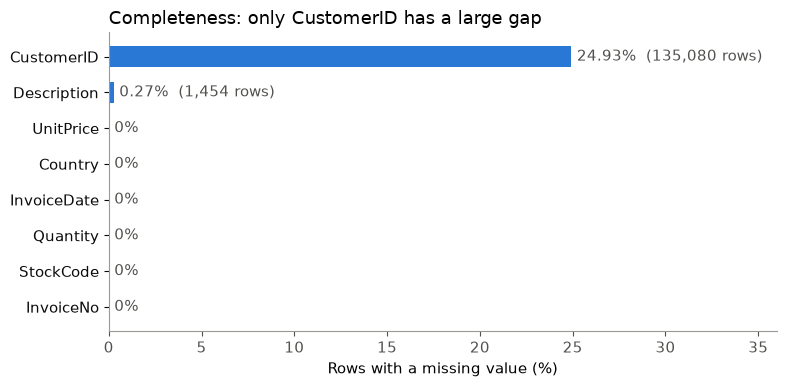

In [13]:
# Shared chart style
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#9a9993", "xtick.color": "#52514e", "ytick.color": "#0b0b0b"})
DIM_COLOURS = {"Completeness": "#2a78d6", "Uniqueness": "#eb6834", "Validity": "#7a5bd6", "Accuracy": "#1baf7a", "Consistency": "#eda100"}

# Chart 1: completeness
ordered = missing_pct.sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ordered.index, ordered.values, color=DIM_COLOURS["Completeness"], height=0.6)
for i, (col, v) in enumerate(ordered.items()):
    ax.text(v + 0.3, i, f"{v:.2f}%  ({missing[col]:,} rows)" if v else "0%", va="center", color="#52514e")
ax.set_xlim(0, 36)
ax.set_xlabel("Rows with a missing value (%)")
ax.set_title("Completeness: only CustomerID has a large gap", loc="left")
plt.tight_layout()
plt.savefig("figures/chart1_missing_values.png", dpi=200)
plt.show()

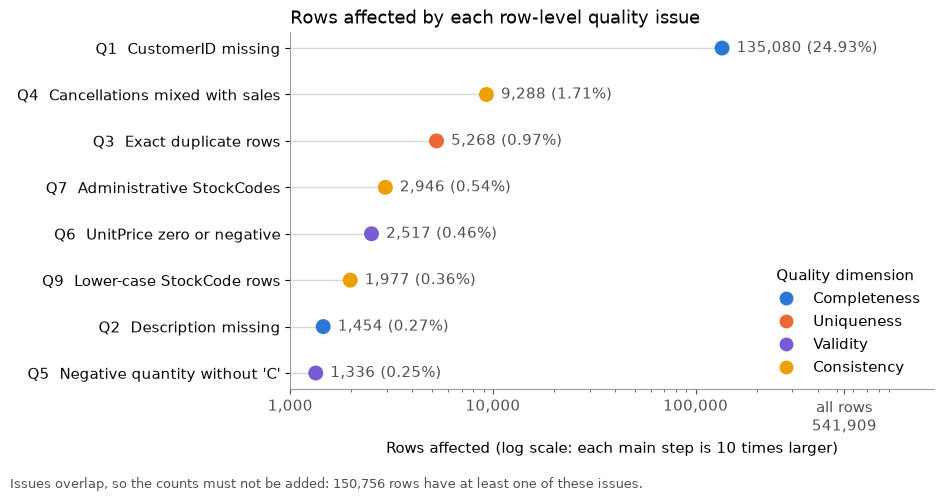

In [14]:
# Chart 2: issue counts, coloured by quality dimension
chart_ids = ["Q1","Q2","Q3","Q4","Q5","Q6","Q7","Q9"]
d = register[register["id"].isin(chart_ids)].sort_values("rows_affected")
fig, ax = plt.subplots(figsize=(9.5, 5))
labels = d["id"] + "  " + d["issue"]
ax.hlines(labels, 1000, d["rows_affected"], color="#d9d8d2", linewidth=1)
ax.scatter(d["rows_affected"], labels, color=d["dimension"].map(DIM_COLOURS), s=95, zorder=3)
for i, v in enumerate(d["rows_affected"]):
    ax.text(v * 1.18, i, f"{v:,} ({v / N:.2%})", va="center", color="#52514e")
ax.set_xscale("log")
ax.set_xlim(1000, 1500000)
ax.set_xticks([1000, 10000, 100000, 541909], ["1,000", "10,000", "100,000", "all rows\n541,909"])
ax.set_xlabel("Rows affected (log scale: each main step is 10 times larger)")
ax.set_title("Rows affected by each row-level quality issue", loc="left")
names = [k for k in DIM_COLOURS if k in set(d["dimension"])]
ax.legend([plt.Line2D([], [], marker="o", linestyle="", color=DIM_COLOURS[k], markersize=9) for k in names], names, frameon=False, loc="lower right", title="Quality dimension")
listed = flags.any(axis=1).sum()
fig.text(0.01, 0.01, f"Issues overlap, so the counts must not be added: {listed:,} rows have at least one of these issues.", fontsize=9, color="#52514e")
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig("figures/chart2_quality_issues.png", dpi=200)
plt.show()


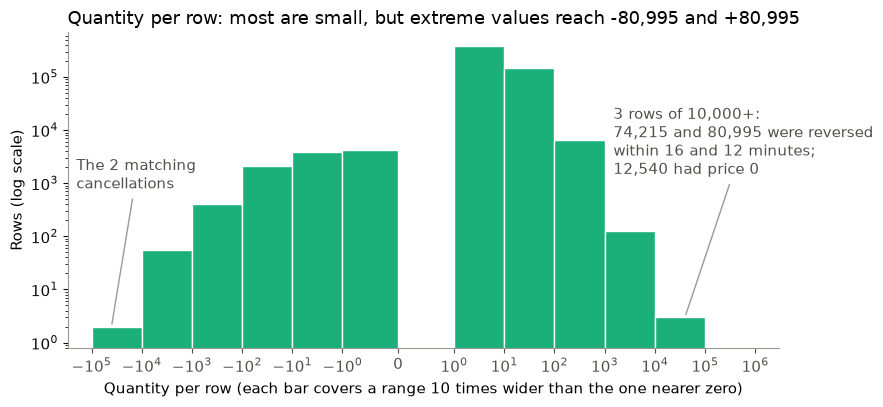

In [15]:
# Chart 3: extreme quantities on symmetric-log axes
fig, ax = plt.subplots(figsize=(9, 4.2))
bins = [-100000,-10000,-1000,-100,-10,-1,0,1,10,100,1000,10000,100000]
ax.hist(df["Quantity"], bins=bins, color="#1baf7a", edgecolor="white", linewidth=1)
ax.set_xscale("symlog", linthresh=1)
ax.set_yscale("log")
ax.set_xlabel("Quantity per row (each bar covers a range 10 times wider than the one nearer zero)")
ax.set_ylabel("Rows (log scale)")
ax.set_title("Quantity per row: most are small, but extreme values reach -80,995 and +80,995", loc="left")
ax.set_xlim(-300000, 3000000)
ax.set_ylim(bottom=0.8)
ax.annotate("3 rows of 10,000+:\n74,215 and 80,995 were reversed\nwithin 16 and 12 minutes;\n12,540 had price 0", xy=(40000, 3), xytext=(1500, 1500), color="#52514e", arrowprops=dict(arrowstyle="-", color="#9a9993"))
ax.annotate("The 2 matching\ncancellations", xy=(-40000, 2), xytext=(-200000, 800), color="#52514e", arrowprops=dict(arrowstyle="-", color="#9a9993"))
plt.tight_layout()
plt.savefig("figures/chart3_quantity_extremes.png", dpi=200)
plt.show()

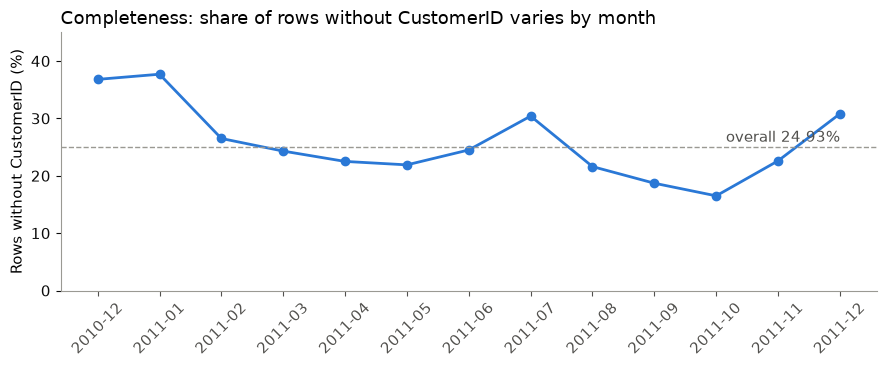

In [16]:
# Chart 4: row-level share of missing CustomerID by month
fig, ax = plt.subplots(figsize=(9, 3.8))
x = missing_by_month.index.astype(str)
ax.plot(x, missing_by_month.values, color=DIM_COLOURS["Completeness"], linewidth=2, marker="o", markersize=6)
ax.axhline(missing_pct["CustomerID"], color="#9a9993", linestyle="--", linewidth=1)
ax.text(len(x) - 1, missing_pct["CustomerID"] + 1, f"overall {missing_pct['CustomerID']}%", ha="right", color="#52514e")
ax.set_ylim(0, 45)
ax.set_ylabel("Rows without CustomerID (%)")
ax.set_title("Completeness: share of rows without CustomerID varies by month", loc="left")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("figures/chart4_missing_customer_by_month.png", dpi=200)
plt.show()